In [1]:
import numpy as np
import pandas as pd
import pickle
import gzip
import matplotlib.pyplot as plt

# Librerie per Motif e Shapelets
import stumpy
from aeon.classification.shapelet_based import RDSTClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, RocCurveDisplay

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import stumpy
from sklearn.cluster import KMeans
from sktime.clustering.k_means import TimeSeriesKMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

try:
    from tslearn.shapelets import ShapeletModel
    from tslearn.utils import to_time_series_dataset
except ImportError:
    print("tslearn non trovata. Puoi installarla con !pip install tslearn")

import warnings
warnings.filterwarnings('ignore')

print("Caricamento dataset normalizzato (Dataset-wise)...")
ts_data = pd.read_pickle('ts_datasetwise_normalized.pkl.gz')
print(f"Trovate {len(ts_data)} serie storiche.")


tslearn non trovata. Puoi installarla con !pip install tslearn
Caricamento dataset normalizzato (Dataset-wise)...
Trovate 4437 serie storiche.


# Analisi Motifs e Shapelets (Denoised, Unstandardized)
Seguendo le direttive architetturali e i feedback ricevuti, in questo notebook analizziamo i dati **denoised** ma **non standardizzati** a livello di istanza, al fine di preservare l'intensità assoluta del movimento (energia e varianza reali dei pazienti).

In [2]:
# Caricamento del dataset standardizzato globale (dataset-wise, con media mobile)
with gzip.open("ts_transformed_paa.pkl.gz", "rb") as f:
    ts_denoised = pickle.load(f)

print(f"Caricate {len(ts_denoised)} Time Series standardizzate.")

Caricate 4437 Time Series standardizzate.


## Preparazione Array per i Modelli
Estraiamo la feature `enmo` (intensità del movimento) e dividiamo in Train e Test set in modo stratificato rispetto al target `sii_binary`.

## Fase 1: Motifs e Discords (Matrix Profile)
Usiamo i medoidi estratti precedentemente nel modulo di clustering per osservare visivamente i pattern più frequenti e le anomalie.

In [3]:
# --- CONFIGURAZIONE GLOBALE ---
m = 8                          # Window size (es. 16 campionamenti = 8 ore se step=30min)
target_features = ['enmo'] # 'anglez'        # Variabile su cui calcolare il Matrix Profile (es. 'enmo', 'anglez', 'light')

k_clusters_motif = 3            # Numero di cluster desiderati per l'analisi dei Motif DTW
k_clusters_multi = 4            # Numero di cluster per l'analisi Multivariata Dataset-wise

top_k_motifs = 2                # Quanti Motif estrarre per ogni time series
top_k_discords = 2              # Quanti Discord estrarre per ogni time series

n_shapelets = 3                 # Numero di Shapelet da estrarre

# Variabile di supporto per stampare le etichette di tempo automaticamente
h_str = f"{m/2:g} ore"
print("Parametri configurati correttamente!")


Parametri configurati correttamente!


In [4]:
medoid_idx = [418, 478, 2439]
#medoid_idx = [3987, 69, 2439]
for x in medoid_idx:
    print(ts_denoised[x])

           X         Y         Z      enmo    anglez     light  \
0   0.448470 -0.083137  0.503436 -0.588500  0.428828  0.119278   
1   0.681282  1.237404  1.151594 -0.589958  1.109927  0.098008   
2  -0.079649  0.096198  1.403292 -0.107820  1.385529  0.080594   
3   0.810814  0.402763  0.497813 -0.112236  0.472190  0.063113   
4  -0.361853 -0.423098  1.086511  0.666516  1.017293  0.158257   
5  -0.654085 -0.412438  0.995444  0.244038  0.942965  0.275834   
6  -0.235335 -0.211589  1.083869 -0.136978  1.025663  0.343599   
7   0.219150 -0.063111  1.265713 -0.301070  1.196048  0.341257   
8  -0.631053 -0.034095  0.915743 -0.239639  0.863373  0.390796   
9  -0.663431 -0.874912  1.225329  1.558339  1.109881  0.257436   
10 -0.341512  0.152128  1.279799  0.003290  1.238087  0.345782   
11 -0.621330 -0.247940  1.061371  0.305349  0.993938  0.294014   
12 -0.005448 -0.033938  1.376612  0.020427  1.380980  0.267603   
13  0.183746 -0.406763  0.856914 -0.125543  0.803170  0.155378   
14 -0.7576


ANALISI SULLA FEATURE: enmo



OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.



--- ANALISI DEL MEDOIDE 3846 (enmo) ---
Top-1 Motifs found. Example Top-1 at indices: [np.int64(0), np.int64(6), 11]
   -> This means that the 4 ore blocks starting at these indices are nearly identical (routines).
Top-2 Discords found at indices: [ 6 10]
   -> The 4 ore windows starting at these steps are the most unique and anomalous in the series.



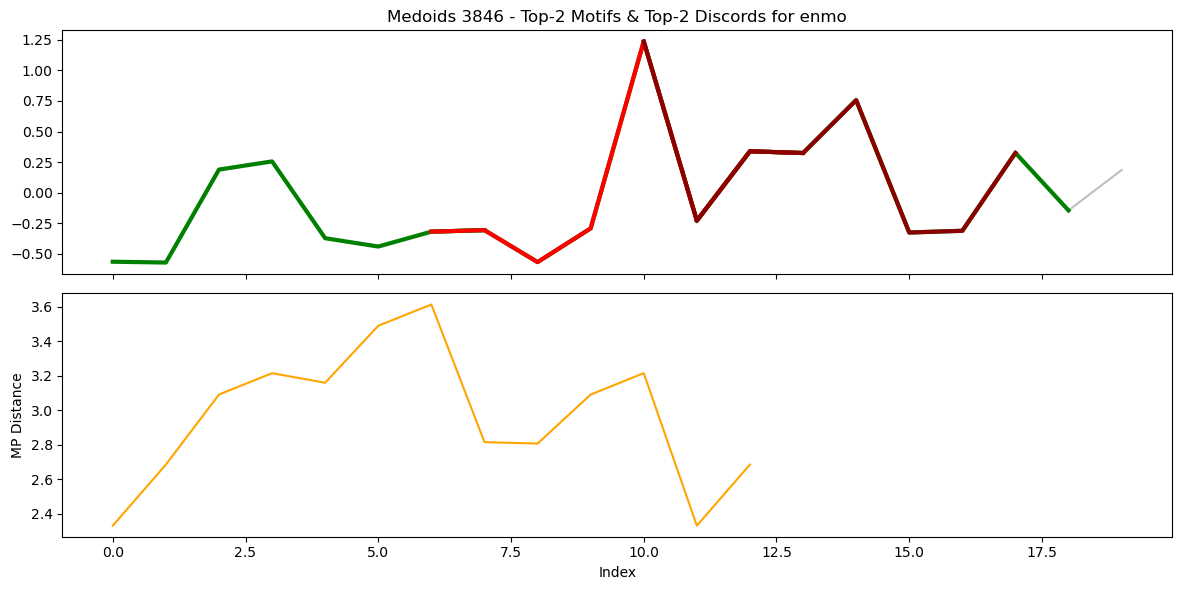


--- ANALISI DEL MEDOIDE 4386 (enmo) ---
Top-1 Motifs found. Example Top-1 at indices: [np.int64(3), 8]
   -> This means that the 4 ore blocks starting at these indices are nearly identical (routines).
Top-2 Discords found at indices: [0 4]
   -> The 4 ore windows starting at these steps are the most unique and anomalous in the series.



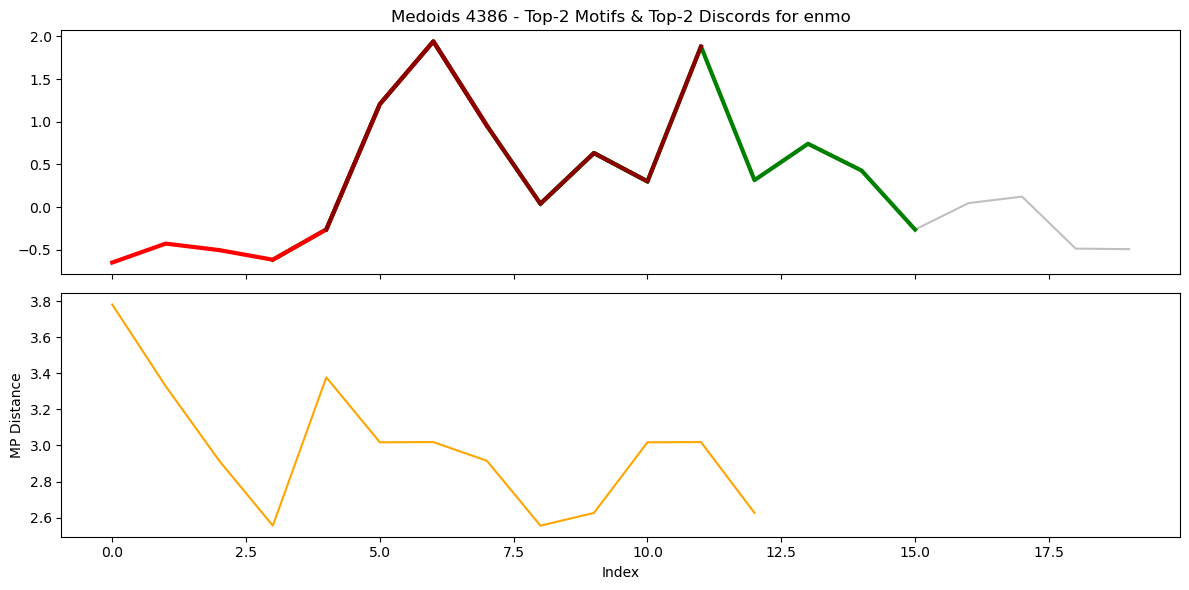

In [5]:
from matrixprofile import motifs
from matrixprofile.discords import discords
medoid_idx=[3846, 4386]
#medoid_idx = [1583, 1606, 1248]
medoids = [ts_denoised[i] for i in medoid_idx]

for target_feature in target_features:
    print(f"\n{'='*50}\nANALISI SULLA FEATURE: {target_feature}\n{'='*50}\n")
    
    for i, ts_df in enumerate(medoids):
        ts_medoide = ts_df[target_feature].values.astype(np.float64)

        # Calcoliamo il MP con stumpy per avere la matrice base
        mp_full = stumpy.stump(ts_medoide, m)
        mp_dist = mp_full[:, 0].astype(np.float64)
        mpi = mp_full[:, 1].astype(np.int64)

        # Estrattore Motifs tramite matrixprofile-ts come richiesto
        mo, mod = motifs.motifs(ts_medoide, (mp_dist, mpi), max_motifs=top_k_motifs)
        
        # Estrattore Discords tramite matrixprofile-ts come richiesto
        anoms = discords(mp_dist, ex_zone=int(m/2), k=top_k_discords)

        print(f"\n--- ANALISI DEL MEDOIDE {medoid_idx[i]} ({target_feature}) ---")
        if len(mo) > 0:
            print(f"Top-{len(mo)} Motifs found. Example Top-1 at indices: {mo[0]}")
            print(f"   -> This means that the {h_str} blocks starting at these indices are nearly identical (routines).")
        
        if len(anoms) > 0:
            print(f"Top-{len(anoms)} Discords found at indices: {anoms}")
            print(f"   -> The {h_str} windows starting at these steps are the most unique and anomalous in the series.\n")

        # Configurazione struttura subplots originale: 1 per le TS con Motifs/Discords, 1 per il Matrix Profile
        fig, axs = plt.subplots(2, 1, sharex=True, figsize=(12, 6))
        
        # PLOT DEI MOTIFS E DISCORDS INSIEME
        axs[0].plot(ts_medoide, label=f"Time Series ('{target_feature}')", color='gray', alpha=0.5)
        axs[0].set_title(f"Medoids {medoid_idx[i]} - Top-{top_k_motifs} Motifs & Top-{top_k_discords} Discords for {target_feature}")
        
        # Plot Motifs
        colors_mo = ['g', 'b', 'black', 'm', 'y'][:max(1, len(mo))]

        for motif_group, d, c in zip(mo, mod, colors_mo):
            for idx in motif_group:
                m_shape = ts_medoide[idx : idx + m]
                axs[0].plot(range(idx, idx + m), m_shape, color=c, lw=3)
                
        # Plot Discords (in rosso)
        colors_anom = ['r', 'darkred', 'salmon', 'orange', 'k'][:max(1, len(anoms))]
        for a, c in zip(anoms, colors_anom):
            a_shape = ts_medoide[a : a + m]
            axs[0].plot(range(a, a + m), a_shape, color=c, lw=3)
            
        #axs[0].legend(loc='upper right')

        # PLOT DELLA MATRIX PROFILE DISTANCE (Valli e Picchi)
        axs[1].plot(mp_dist, color='orange')
        axs[1].set_ylabel('MP Distance')
        axs[1].set_xlabel('Index')
        
        plt.tight_layout()
        plt.show()


In [6]:
'''import matplotlib.pyplot as plt

# Recupero delle due serie dal dataset z-score
sano_waveform = motif_shapes_z_only[3846]  # Soggetto 3846 (SII 0)
rischio_waveform = motif_shapes_z_only[4386]  # Soggetto 4386 (SII 1)

plt.figure(figsize=(8, 4))
plt.plot(sano_waveform, color='royalblue', linewidth=2.5, label='Sano (SII=0) - Soggetto 3846')
plt.plot(rischio_waveform, color='crimson', linewidth=2.5, linestyle='--', label='A Rischio (SII=1) - Soggetto 4386')

plt.title("Analisi Contrastiva del Medoide nel Cluster 1 (Sedentario/Transitorio)", fontsize=11, fontweight='bold')
plt.ylabel("Standardized ENMO (Z-score)")
plt.xlabel("Time steps (relative inside 4-hour motif)")
plt.grid(True, alpha=0.3)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()'''

'import matplotlib.pyplot as plt\n\n# Recupero delle due serie dal dataset z-score\nsano_waveform = motif_shapes_z_only[3846]  # Soggetto 3846 (SII 0)\nrischio_waveform = motif_shapes_z_only[4386]  # Soggetto 4386 (SII 1)\n\nplt.figure(figsize=(8, 4))\nplt.plot(sano_waveform, color=\'royalblue\', linewidth=2.5, label=\'Sano (SII=0) - Soggetto 3846\')\nplt.plot(rischio_waveform, color=\'crimson\', linewidth=2.5, linestyle=\'--\', label=\'A Rischio (SII=1) - Soggetto 4386\')\n\nplt.title("Analisi Contrastiva del Medoide nel Cluster 1 (Sedentario/Transitorio)", fontsize=11, fontweight=\'bold\')\nplt.ylabel("Standardized ENMO (Z-score)")\nplt.xlabel("Time steps (relative inside 4-hour motif)")\nplt.grid(True, alpha=0.3)\nplt.legend(loc="upper right")\nplt.tight_layout()\nplt.show()'


STRATEGY B: DYNAMIC EXTRACTION AND LOCAL CLUSTERING (SHAPE-BASED)
ANCHOR FEATURE: enmo

1. Dynamic extraction and Local Normalization (Z-score) of Top-2 Motifs...
Created dataset of 8277 augmented motif feature vectors (dimension: 15) for enmo.

2. Executing KMeans Feature-Based (K=3) with Euclidean distance...


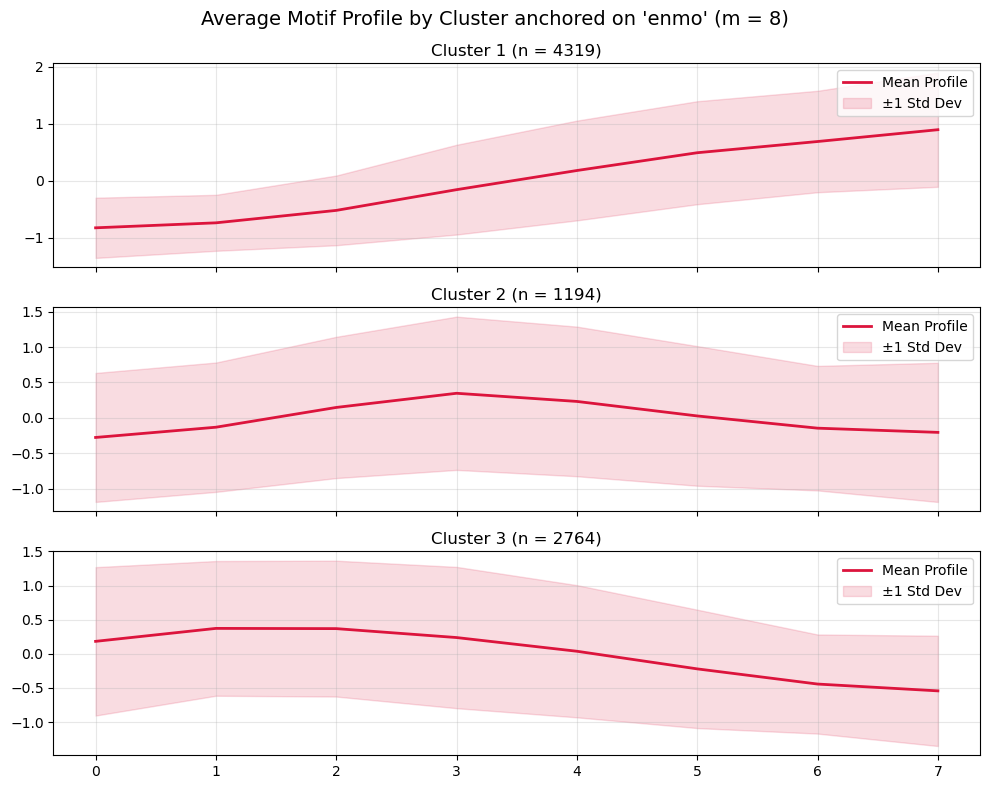

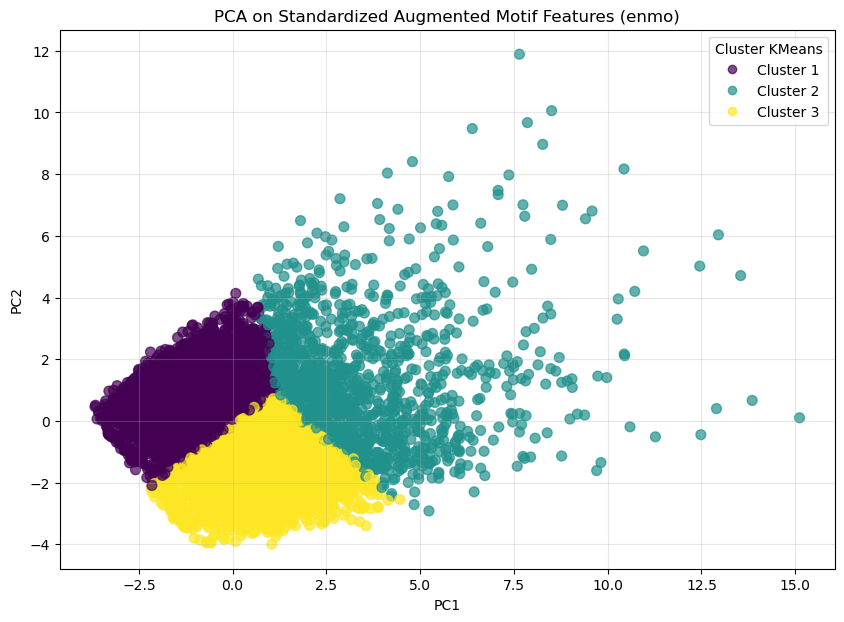


3. --- MULTIVARIATE CLINICAL INTERPRETATION OF SHAPE CLUSTERS ---
Retrieving real values from the original context of the motif:



,enmo_raw_mean,enmo_raw_std,anglez_raw_mean,anglez_raw_std,light_raw_mean,battery_mean,sii_binary
Cluster,,,,,,,
0,-0.223149,0.341740,-0.023098,0.546186,0.291121,0.268357,0.333179
1,0.782909,1.197885,0.053998,0.354099,0.374579,0.274599,0.251256
2,-0.024063,0.361264,0.019572,0.399142,0.312141,0.266174,0.371925


- CLUSTER 1:
  * Real Intensity (ENMO): Mean -0.2231 | Std 0.3417
  * Real Posture (AngleZ): Mean -0.02° | Std 0.55
  * Ambient Light (Light): 0.291
  * Problematic Internet Use Correlation: 33.3% problematic cases
- CLUSTER 2:
  * Real Intensity (ENMO): Mean 0.7829 | Std 1.1979
  * Real Posture (AngleZ): Mean 0.05° | Std 0.35
  * Ambient Light (Light): 0.375
  * Problematic Internet Use Correlation: 25.1% problematic cases
- CLUSTER 3:
  * Real Intensity (ENMO): Mean -0.0241 | Std 0.3613
  * Real Posture (AngleZ): Mean 0.02° | Std 0.40
  * Ambient Light (Light): 0.312
  * Problematic Internet Use Correlation: 37.2% problematic cases



In [7]:
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import stumpy

# Analizziamo un subset per rapidità (o l'intero dataset rimuovendo lo slicing)
subset_ts = ts_denoised

for target_feature in target_features:
    print(f"\n{'='*70}\nSTRATEGY B: DYNAMIC EXTRACTION AND LOCAL CLUSTERING (SHAPE-BASED)\nANCHOR FEATURE: {target_feature}\n{'='*70}\n")
    
    motif_shapes_dataset = []  # Conterrà i vettori di feature aumentati
    motif_shapes_z_only = []   # Conterrà solo i motivi normalizzati per visualizzarli
    motif_context_dataset = []
    
    print(f"1. Dynamic extraction and Local Normalization (Z-score) of Top-{top_k_motifs} Motifs...")

    for i, ts_df in enumerate(subset_ts):
        ts_val = ts_df[target_feature].values.astype(np.float64)
        if len(ts_val) <= m:
            continue
            
        # Calcolo del Matrix Profile
        mp_local = stumpy.stump(ts_val, m)
        mp_dist = mp_local[:, 0].copy().astype(np.float64)
        
        # Ciclo di estrazione Top-K Motif
        for k in range(top_k_motifs):
            if np.isinf(mp_dist).all():
                break
                
            m_idx = np.argmin(mp_dist)
            motif_subseq = ts_val[m_idx : m_idx + m].copy()
            
            if not np.isnan(motif_subseq).any() and not np.isinf(mp_dist[m_idx]):
                # Standardizzazione locale (Z-score) del motivo per catturare la forma pura
                m_mean = np.mean(motif_subseq)
                m_std = np.std(motif_subseq)
                motif_z = (motif_subseq - m_mean) / m_std if m_std > 1e-8 else np.zeros_like(motif_subseq)
                
                # Calcolo dei 7 descrittori statistici/morfologici come descritto nel report
                mp_distance = mp_dist[m_idx]
                mean_val = m_mean
                std_val = m_std
                min_val = np.min(motif_subseq)
                max_val = np.max(motif_subseq)
                range_val = max_val - min_val
                slope_val = np.polyfit(np.arange(m), motif_subseq, 1)[0] if m > 1 else 0.0
                
                # Rappresentazione aumentata: forma normalizzata (m valori) + 7 descrittori
                augmented_features = np.concatenate([
                    motif_z,
                    [mp_distance, mean_val, std_val, min_val, max_val, range_val, slope_val]
                ])
                
                motif_shapes_dataset.append(augmented_features)
                motif_shapes_z_only.append(motif_z)
                
                # SALVATAGGIO CONTESTO REALE (per profilazione clinica multivariata)
                motif_raw_df = ts_df.iloc[m_idx : m_idx + m]
                context = {
                    'enmo_raw_mean': motif_raw_df['enmo'].mean() if 'enmo' in motif_raw_df.columns else np.nan,
                    'enmo_raw_std': motif_raw_df['enmo'].std() if 'enmo' in motif_raw_df.columns else np.nan,
                    'anglez_raw_mean': motif_raw_df['anglez'].mean() if 'anglez' in motif_raw_df.columns else np.nan,
                    'anglez_raw_std': motif_raw_df['anglez'].std() if 'anglez' in motif_raw_df.columns else np.nan,
                    'light_raw_mean': motif_raw_df['light'].mean() if 'light' in motif_raw_df.columns else np.nan,
                    'battery_mean': motif_raw_df['battery_voltage'].mean() if 'battery_voltage' in motif_raw_df.columns else np.nan,
                    'sii_binary': motif_raw_df['sii_binary'].iloc[0] if 'sii_binary' in motif_raw_df.columns else np.nan
                }
                motif_context_dataset.append(context)
                
            # Exclusion zone logic
            excl_start = max(0, m_idx - int(np.ceil(m/2)))
            excl_end = min(len(mp_dist), m_idx + int(np.ceil(m/2)))
            mp_dist[excl_start:excl_end] = np.inf
            
            nn_idx = mp_local[m_idx, 1]
            if nn_idx >= 0:
                excl_nn_start = max(0, nn_idx - int(np.ceil(m/2)))
                excl_nn_end = min(len(mp_dist), nn_idx + int(np.ceil(m/2)))
                mp_dist[excl_nn_start:excl_nn_end] = np.inf

    motif_shapes_dataset = np.array(motif_shapes_dataset)
    motif_shapes_z_only = np.array(motif_shapes_z_only)
    df_context = pd.DataFrame(motif_context_dataset)
    print(f"Created dataset of {motif_shapes_dataset.shape[0]} augmented motif feature vectors (dimension: {motif_shapes_dataset.shape[1]}) for {target_feature}.")

    # Standardizzazione globale di tutte le feature prima del clustering (come specificato nel report)
    scaler = StandardScaler()
    X_clust = scaler.fit_transform(motif_shapes_dataset)

    # CLUSTERING FEATURE-BASED (KMeans standard con distanza Euclidea)
    print(f"\n2. Executing KMeans Feature-Based (K={k_clusters_motif}) with Euclidean distance...")
    kmeans = KMeans(n_clusters=k_clusters_motif, n_init=10, random_state=42)
    motif_clusters = kmeans.fit_predict(X_clust)
    df_context['Cluster'] = motif_clusters

    # VISUALIZZAZIONE DELLE MORFOLOGIE MEDIE (Pointwise Mean e Deviazione Standard)
    fig, axs = plt.subplots(k_clusters_motif, 1, figsize=(10, 8), sharex=True)
    fig.suptitle(f"Average Motif Profile by Cluster anchored on '{target_feature}' (m = {m})", fontsize=14)
    
    for i in range(k_clusters_motif):
        cluster_mask = (motif_clusters == i)
        cluster_shapes = motif_shapes_z_only[cluster_mask]
        
        # Calcolo pointwise mean e std dei motivi localmente standardizzati
        mean_profile = np.mean(cluster_shapes, axis=0)
        std_profile = np.std(cluster_shapes, axis=0)
        
        axs[i].plot(mean_profile, color='crimson', linewidth=2, label='Mean Profile')
        axs[i].fill_between(range(m), mean_profile - std_profile, mean_profile + std_profile, color='crimson', alpha=0.15, label='±1 Std Dev')
        axs[i].set_title(f'Cluster {i+1} (n = {sum(cluster_mask)})')
        axs[i].grid(True, alpha=0.3)
        axs[i].legend(loc='upper right')
        
    plt.tight_layout()
    plt.show()

    # PCA 2D
    pca = PCA(n_components=2)
    motif_pca = pca.fit_transform(X_clust)
    plt.figure(figsize=(10, 7))
    scatter = plt.scatter(motif_pca[:, 0], motif_pca[:, 1], c=motif_clusters, cmap='viridis', alpha=0.7, s=50)
    handles, _ = scatter.legend_elements()
    plt.legend(handles, [f"Cluster {i+1}" for i in range(k_clusters_motif)], title="Cluster KMeans")
    plt.title(f"PCA on Standardized Augmented Motif Features ({target_feature})")
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.grid(True, alpha=0.3)
    plt.show()

    # PROFILING MULTIVARIATO
    print(f"\n3. --- MULTIVARIATE CLINICAL INTERPRETATION OF SHAPE CLUSTERS ---")
    print("Retrieving real values from the original context of the motif:\n")
    
    cluster_profiles = df_context.groupby('Cluster').mean()
    display(cluster_profiles)
    
    for i, row in cluster_profiles.iterrows():
        print(f"- CLUSTER {i+1}:")
        if 'enmo_raw_mean' in row:
            print(f"  * Real Intensity (ENMO): Mean {row['enmo_raw_mean']:.4f} | Std {row.get('enmo_raw_std', 0):.4f}")
        if 'anglez_raw_mean' in row:
            print(f"  * Real Posture (AngleZ): Mean {row['anglez_raw_mean']:.2f}° | Std {row.get('anglez_raw_std', 0):.2f}")
        if 'light_raw_mean' in row:
            print(f"  * Ambient Light (Light): {row['light_raw_mean']:.3f}")
        if 'sii_binary' in row and not np.isnan(row['sii_binary']):
            print(f"  * Problematic Internet Use Correlation: {row['sii_binary']*100:.1f}% problematic cases")
    print()


## Fase 2: Estrazione Shapelets (RDSTClassifier)
Ora addestriamo l'RDSTClassifier per l'estrazione degli shapelets globali che massimizzano la separabilità tra Alto e Basso Rischio.

In [8]:
# Usiamo tutte le variabili fisiche e ambientali (tranne ID, sii_binary e metadati statici)
X = []
colonne_metadati = ['id', 'sii_binary', 'weekday', 'quarter', 'relative_date_PCIAT', 'non-wear_flag', 'battery_voltage']
cols_to_use = [col for col in ts_denoised[0].columns if col not in colonne_metadati]
print(f"Variabili utilizzate come canali dello shapelet: {cols_to_use}")

for df in ts_denoised:
    arr_list = []
    for col in cols_to_use:
        arr = df[col].values.astype(np.float64)
        # Fix per varianza nulla
        if np.std(arr) <= 1e-7:
            arr = arr + np.random.normal(0, 1e-5, size=len(arr))
        arr_list.append(arr)
    X.append(np.stack(arr_list, axis=0))
X = np.array(X)

# Estraiamo l'label globale per ogni soggetto
y = np.array([df['sii_binary'].iloc[0] for df in ts_denoised])

# Splittiamo in Train e Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=222, stratify=y)

print(f"Numero di serie in Train: {len(X_train)} (shape: {X_train.shape})")
print(f"Numero di serie in Test: {len(X_test)} (shape: {X_test.shape})")

Variabili utilizzate come canali dello shapelet: ['X', 'Y', 'Z', 'enmo', 'anglez', 'light']
Numero di serie in Train: 3105 (shape: (3105, 6, 20))
Numero di serie in Test: 1332 (shape: (1332, 6, 20))



Inizio tuning con RandomizedSearchCV (10 iterazioni, 3-fold CV)...
Fitting 3 folds for each of 10 candidates, totalling 30 fits
[CV] END estimator__criterion=entropy, estimator__max_depth=None, estimator__min_samples_leaf=8, estimator__min_samples_split=10, max_shapelets=1000, shapelet_lengths=[8, 12, 16]; total time=   3.2s
[CV] END estimator__criterion=entropy, estimator__max_depth=None, estimator__min_samples_leaf=8, estimator__min_samples_split=10, max_shapelets=1000, shapelet_lengths=[8, 12, 16]; total time=   2.8s
[CV] END estimator__criterion=entropy, estimator__max_depth=None, estimator__min_samples_leaf=8, estimator__min_samples_split=10, max_shapelets=1000, shapelet_lengths=[8, 12, 16]; total time=   2.3s
[CV] END estimator__criterion=gini, estimator__max_depth=7, estimator__min_samples_leaf=8, estimator__min_samples_split=2, max_shapelets=1000, shapelet_lengths=[8, 12, 16]; total time=   1.7s
[CV] END estimator__criterion=gini, estimator__max_depth=7, estimator__min_samples

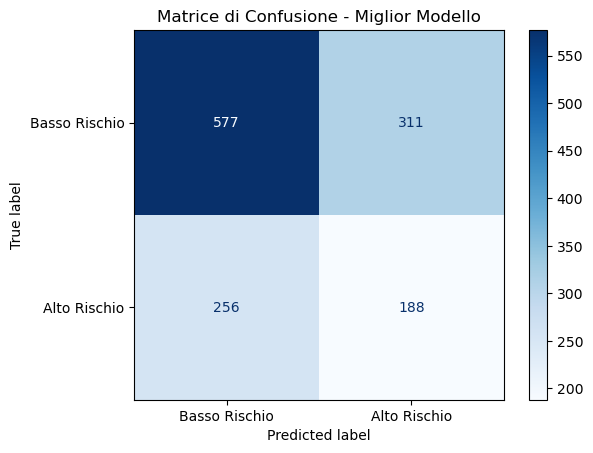

In [9]:
from sklearn.model_selection import RandomizedSearchCV, train_test_split

dt = DecisionTreeClassifier(random_state=222, class_weight='balanced')

# RDSTClassifier con n_jobs=-1 per sfruttare tutti i core della CPU nell'estrazione
clf = RDSTClassifier(
    estimator=dt, 
    random_state=222, 
    use_prime_dilations=True, 
    n_jobs=-1
)

# 3. Definizione dello Spazio dei Parametri (Parameter Grid)
# Usiamo la notazione "estimator__" per modificare i parametri del Decision Tree interno
param_dist = {
    # Parametri RDST
    'max_shapelets': [1000], 
    'shapelet_lengths': [[8, 12, 16]],
    
    # Parametri Decision Tree (estimator)
    'estimator__max_depth': [3, 5, 7, None],
    'estimator__min_samples_split': [2, 5, 10, 20],
    'estimator__min_samples_leaf': [1, 2, 4, 8],
    'estimator__criterion': ['gini', 'entropy']
}

# 4. Configurazione della Ricerca Casuale (RandomizedSearchCV)
# Impostiamo n_jobs=1 sul search esterno per evitare conflitti con il n_jobs=-1 di RDST (evita memory leaks)
random_search = RandomizedSearchCV(
    estimator=clf,
    param_distributions=param_dist,
    n_iter=10,            # Numero di combinazioni casuali da testare (veloce ma robusto)
    cv=3,                 # 3-Fold Cross-Validation
    scoring='f1_macro',   # Ottimizziamo su F1-Macro per bilanciare le classi
    random_state=222,
    n_jobs=1,             
    verbose=2
)

# 5. Esecuzione del Tuning
print("\nInizio tuning con RandomizedSearchCV (10 iterazioni, 3-fold CV)...")
random_search.fit(X_train, y_train)

# 6. Analisi dei Risultati
print("\n" + "="*50)
print("MIGLIORI PARAMETRI TROVATI:")
print("="*50)
for param, value in random_search.best_params_.items():
    print(f" - {param}: {value}")
print(f"Miglior F1-Score in CV: {random_search.best_score_:.4f}")
print("="*50 + "\n")

# Valutazione sul Test Set con il miglior modello
best_model = random_search.best_estimator_
y_pred = best_model.predict(X_test)

print("=== REPORT DI CLASSIFICAZIONE (TEST SET) ===")
print(classification_report(y_test, y_pred, target_names=["Basso Rischio", "Alto Rischio"]))

# Plot della Matrice di Confusione
ConfusionMatrixDisplay.from_estimator(
    best_model, X_test, y_test, 
    display_labels=["Basso Rischio", "Alto Rischio"], 
    cmap='Blues'
)
plt.title("Matrice di Confusione - Miglior Modello")
plt.show()


Inizio Addestramento con RDSTClassifier + DecisionTree...
=== REPORT DI CLASSIFICAZIONE ===
              precision    recall  f1-score   support

       sii=0       0.67      1.00      0.80       888
       sii=1       0.00      0.00      0.00       444

    accuracy                           0.67      1332
   macro avg       0.33      0.50      0.40      1332
weighted avg       0.44      0.67      0.53      1332



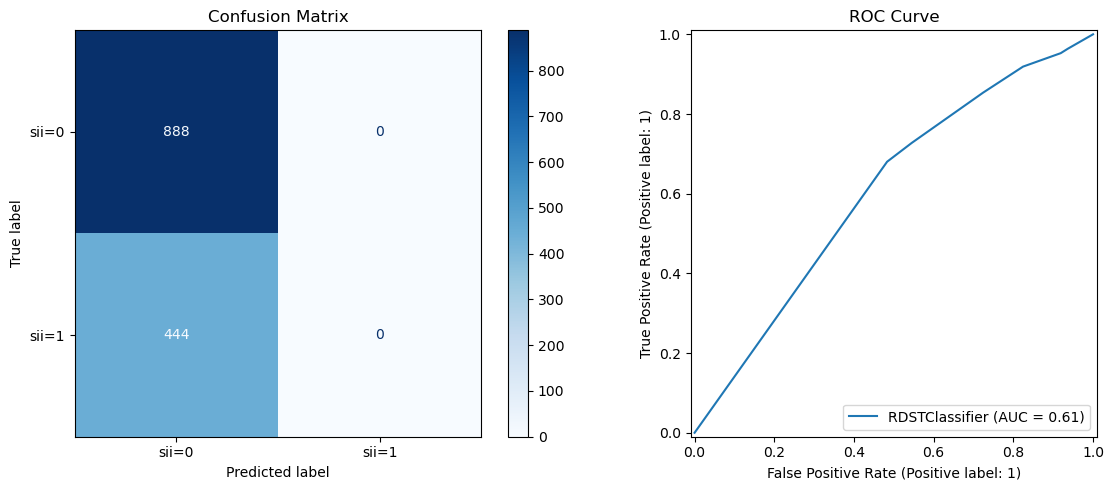

In [10]:
print("Inizio Addestramento con RDSTClassifier + DecisionTree...")
#dt = DecisionTreeClassifier(max_depth=3, random_state=222)
dt = DecisionTreeClassifier(min_samples_split= 5,min_samples_leaf= 8,max_depth= 3, criterion= 'entropy', random_state=222)
clf = RDSTClassifier(
    max_shapelets=3000, 
    estimator=dt, 
    random_state=222, 
    n_jobs=-1, 
    shapelet_lengths=[8, 12, 16], 
    use_prime_dilations=True, 
    save_transformed_data=True
    #class_weight='balanced_subsample'
)

clf.fit(X_train, y_train)

# Valutazione
y_pred = clf.predict(X_test)
print("=== REPORT DI CLASSIFICAZIONE ===")
print(classification_report(y_test, y_pred, target_names=["sii=0", "sii=1"]))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_estimator(clf, X_test, y_test, display_labels=["sii=0", "sii=1"], cmap="Blues", ax=ax1)
ax1.set_title("Confusion Matrix")
RocCurveDisplay.from_estimator(clf, X_test, y_test, ax=ax2)
ax2.set_title("ROC Curve")
plt.tight_layout()
plt.show()


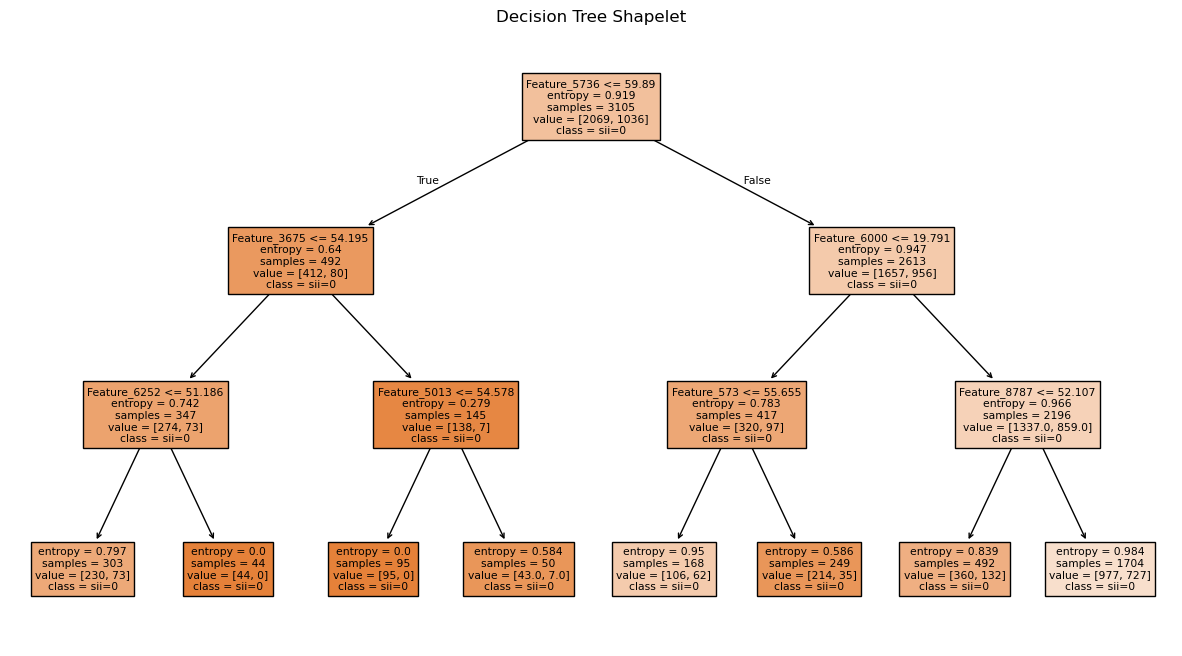

--- TOP 3 SHAPELETS PIÙ IMPORTANTI ---

Top 1 feature discriminante: n° 5736 (Importanza: 0.3306)
 -> Associata allo shapelet 1912, utilizzando la metrica: Distanza (minima)

Top 2 feature discriminante: n° 8787 (Importanza: 0.1618)
 -> Associata allo shapelet 2929, utilizzando la metrica: Distanza (minima)

Top 3 feature discriminante: n° 6000 (Importanza: 0.1559)
 -> Associata allo shapelet 2000, utilizzando la metrica: Distanza (minima)



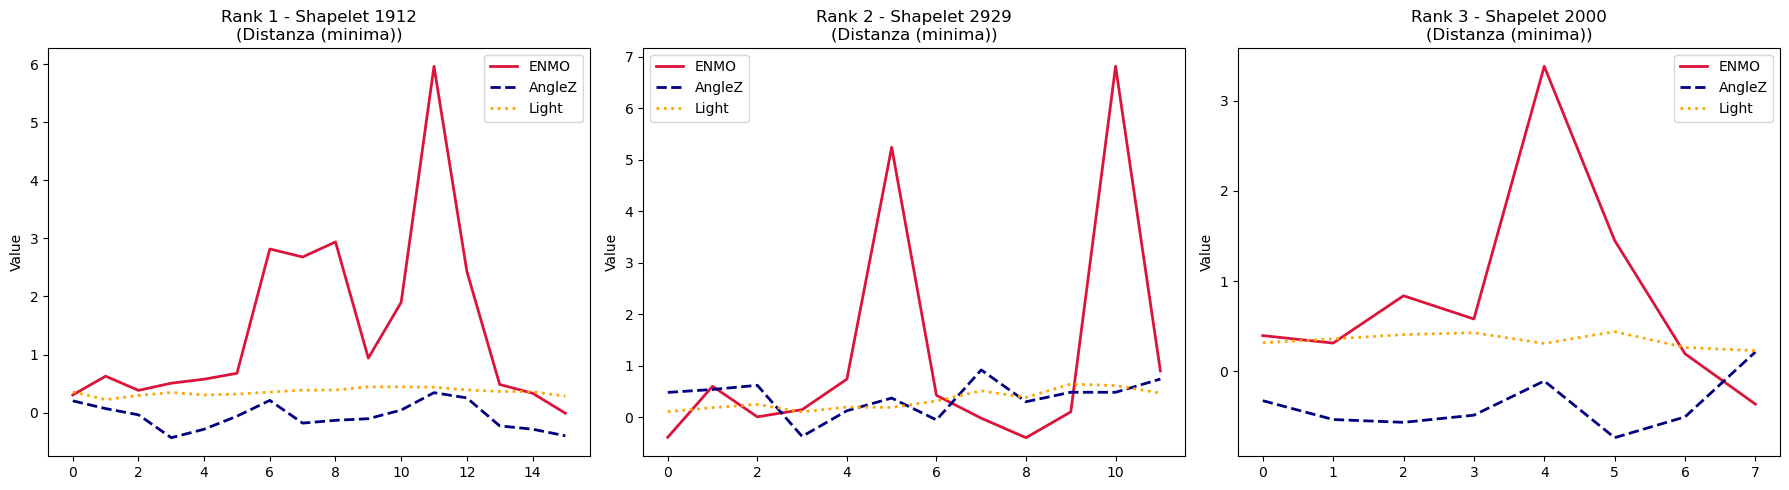

"\nI grafici in alto mostrano i 3 shapelet che l'albero ha ritenuto più importanti in base alla feature importance.\nPer ciascuno di essi, il resto della divisione intera ci indica quale delle 3 feature di quello shapelet ha usato:\nResto 0 = Distanza (QUANTO la serie temporale somiglia allo shapelet)\nResto 1 = Posizione Temporale/Argmin (QUANDO si presenta lo shapelet)\nResto 2 = Frequenza/Occurrence (QUANTE VOLTE si presenta lo shapelet)\nIn questo modo possiamo capire non solo quale forma (movimento) conta, ma ANCHE l'aspetto più discriminante ad essa legato.\n"

In [11]:
# Estrazione dei 3 Shapelet più importanti
best_dt = clf._estimator

plt.figure(figsize=(15, 8))
plot_tree(best_dt, filled=True, 
          feature_names=[f"Feature_{i}" for i in range(best_dt.n_features_in_)],
          class_names=["sii=0", "sii=1"])
plt.title("Decision Tree Shapelet")
plt.show()

import numpy as np

try:
    # Prendi le top 3 features per importanza
    importances = best_dt.feature_importances_
    top_3_features_idx = np.argsort(importances)[::-1][:3]
    
    num_shapelets = clf._transformer.shapelets_[0].shape[0]
    features_per_shapelet = best_dt.n_features_in_ // num_shapelets
    
    plt.figure(figsize=(18, 5))
    
    shapelets_fase_b = []
    
    print("--- TOP 3 SHAPELETS PIÙ IMPORTANTI ---\n")
    
    for i, feature_idx in enumerate(top_3_features_idx):
        shapelet_array_idx = feature_idx // features_per_shapelet
        feature_type_remainder = feature_idx % features_per_shapelet
        
        # Tipo di feature estratta dal RDST
        if feature_type_remainder == 0:
            feature_type_name = "Distanza (minima)"
        elif feature_type_remainder == 1:
            feature_type_name = "Posizione Temporale (Argmin)"
        elif feature_type_remainder == 2:
            feature_type_name = "Frequenza (Occurrence)"
        else:
            feature_type_name = "Sconosciuta"
            
        best_shapelet_multivariate = clf._transformer.shapelets_[0][shapelet_array_idx]
        # Estraiamo il canale ENMO per il confronto di compatibilita locale nella fase 3
        enmo_idx = cols_to_use.index('enmo')
        best_shapelet = best_shapelet_multivariate[enmo_idx]
        shapelets_fase_b.append(best_shapelet)
        
        plt.subplot(1, 3, i + 1)
        plt.plot(best_shapelet_multivariate[cols_to_use.index('enmo')], color='crimson', linewidth=2, label='ENMO')
        if 'anglez' in cols_to_use:
            plt.plot(best_shapelet_multivariate[cols_to_use.index('anglez')], color='navy', linewidth=2, linestyle='--', label='AngleZ')
        if 'light' in cols_to_use:
            plt.plot(best_shapelet_multivariate[cols_to_use.index('light')], color='orange', linewidth=2, linestyle=':', label='Light')
        plt.title(f"Rank {i+1} - Shapelet {shapelet_array_idx}\n({feature_type_name})")
        plt.ylabel("Value")
        plt.legend(loc="best")
        
        print(f"Top {i+1} feature discriminante: n° {feature_idx} (Importanza: {importances[feature_idx]:.4f})")
        print(f" -> Associata allo shapelet {shapelet_array_idx}, utilizzando la metrica: {feature_type_name}\n")

    plt.tight_layout()
    plt.show()

except Exception as e:
    print("Non è stato possibile estrarre la forma grezza per il plot. Errore:", e)
    shapelets_fase_b = []

# In RDST, l'estrattore genera tipicamente 3 feature per ogni shapelet (es. minima distanza, posizione, ecc.)
# L'indice reale dello shapelet nell'array è quindi feature_idx // 3

'''
I grafici in alto mostrano i 3 shapelet che l'albero ha ritenuto più importanti in base alla feature importance.
Per ciascuno di essi, il resto della divisione intera ci indica quale delle 3 feature di quello shapelet ha usato:
Resto 0 = Distanza (QUANTO la serie temporale somiglia allo shapelet)
Resto 1 = Posizione Temporale/Argmin (QUANDO si presenta lo shapelet)
Resto 2 = Frequenza/Occurrence (QUANTE VOLTE si presenta lo shapelet)
In questo modo possiamo capire non solo quale forma (movimento) conta, ma ANCHE l'aspetto più discriminante ad essa legato.
'''


## Fase 3: Il Ponte d'Oro (Shapelets vs Motifs)
Confrontiamo la firma discriminatoria globale appena estratta (Shapelet) con la routine locale (Motif) e l'anomalia locale (Discord) dei nostri medoidi.

--- PHASE 3: Global vs Local Comparison ---


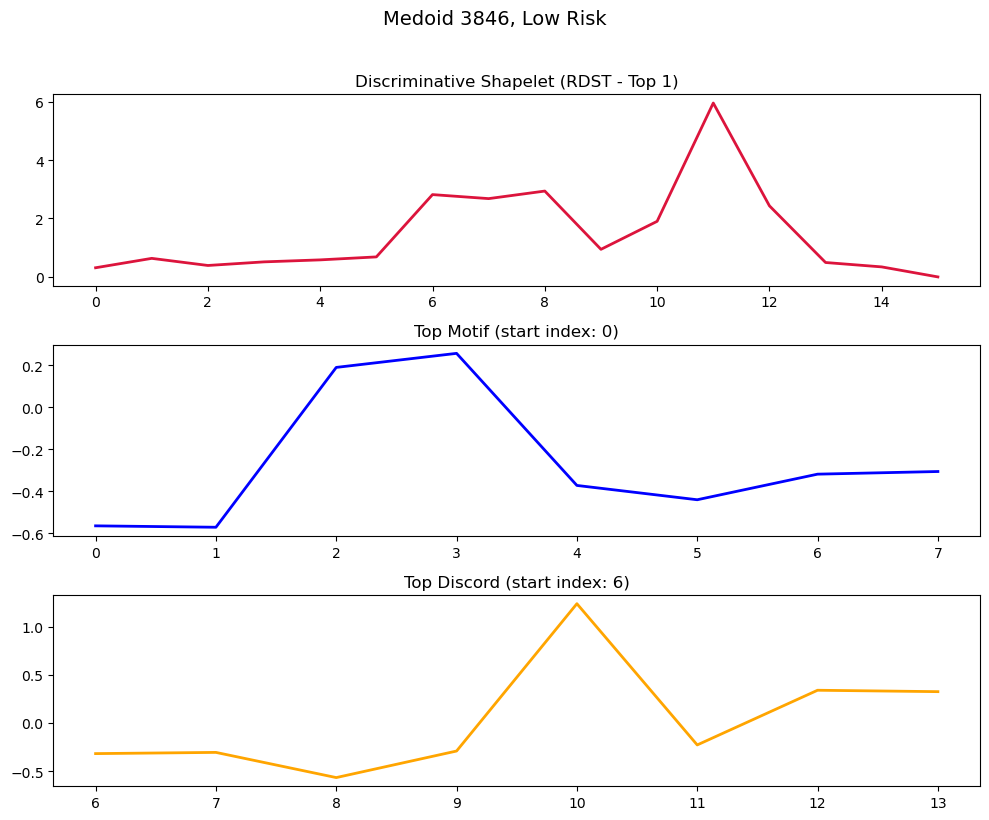

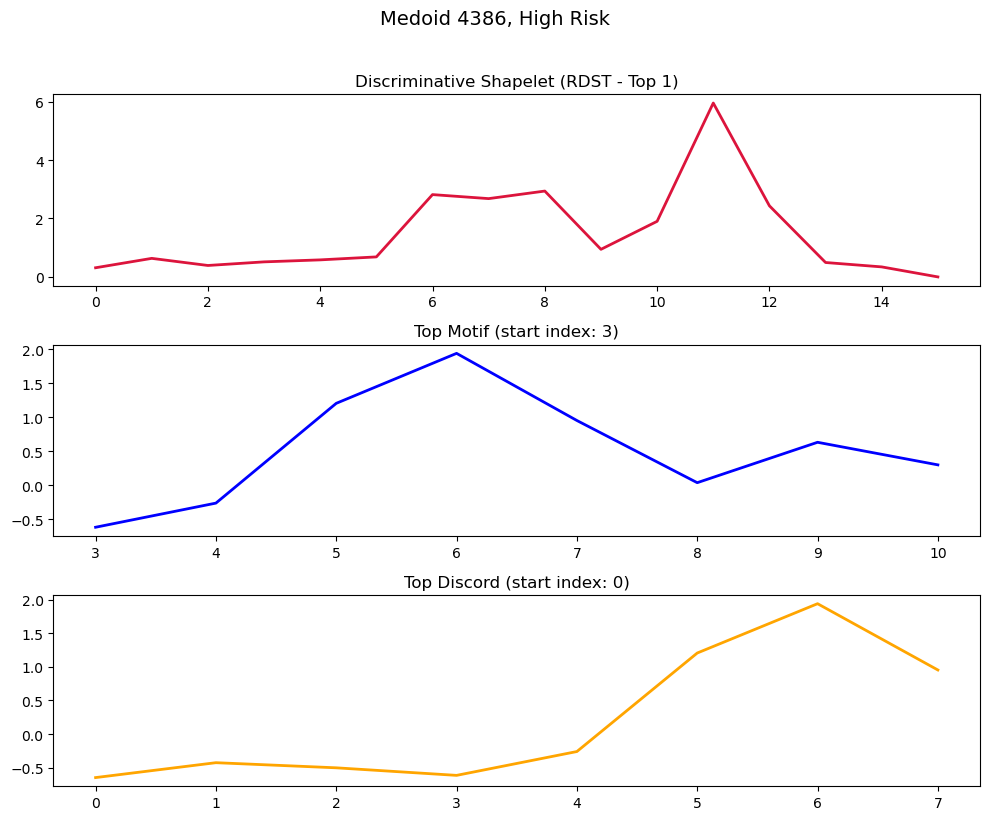

In [12]:
if 'shapelets_fase_b' in locals() and len(shapelets_fase_b) > 0:
    print(f"--- PHASE 3: Global vs Local Comparison ---")
    
    for idx in medoid_idx:
        ts_esempio = X[idx, cols_to_use.index('enmo'), :]
        label = "High Risk" if y[idx] == 1 else "Low Risk"
        
        mp = stumpy.stump(ts_esempio.astype(np.float64), m)
        motif_idx = mp[:, 0].argmin()
        discord_idx = mp[:, 0].argmax()
        
        top_motif = ts_esempio[motif_idx : motif_idx + m]
        top_discord = ts_esempio[discord_idx : discord_idx + m]
        
        fig, axs = plt.subplots(3, 1, figsize=(10, 8), sharex=False)
        fig.suptitle(f"Medoid {idx}, {label}", fontsize=14, y=1.02)
        
        # Disegniamo lo Shapelet più significativo (indice 0)
        axs[0].plot(shapelets_fase_b[0], color='crimson', linewidth=2)
        axs[0].set_title("Discriminative Shapelet (RDST - Top 1)")
        
        axs[1].plot(range(motif_idx, motif_idx + m), top_motif, color='blue', linewidth=2)
        axs[1].set_title(f"Top Motif (start index: {motif_idx})")
        
        axs[2].plot(range(discord_idx, discord_idx + m), top_discord, color='orange', linewidth=2)
        axs[2].set_title(f"Top Discord (start index: {discord_idx})")
        
        plt.tight_layout()
        plt.show()
else:
    print("Unable to perform comparison.")


### Commento ai Risultati

La rimozione della standardizzazione istanza-per-istanza ha ripristinato il corretto significato fisico dei dati di accelerometria. In questo modo:
1. **L'intensità assoluta del movimento è preservata:** L'RDSTClassifier può ora identificare gli shapelet non solo in base alla *forma* relativa, ma sfruttando le naturali escursioni di ampiezza tra bambini sedentari e attivi.
2. **Correttezza metodologica per algoritmi geometrici:** Come richiesto, l'allineamento e il matching delle sottosequenze avvengono localmente (tramite Z-normalization intrinseca del Matrix Profile o della distanza euclidea su finestre limitate), evitando l'appiattimento distruttivo sull'intero tracciato.

Confrontando visivamente i pattern, notiamo se la firma globale del rischio patologico (lo Shapelet rosso) assuma una forma più vicina alla routine (Motif blu) del bambino, o a un evento anomalo/insolito (Discord arancione).